# Laptop Price Prediction — Exploratory Data Analysis (EDA)

## 1. Project Overview

This notebook conducts exploratory data analysis on a dataset of laptop hardware specifications and retail prices to assess data quality, extract predictive features, and investigate price relationships prior to model development.

### Analytical Objectives
1. **Data Quality Assessment:** Verify missing values, whitespace artifacts, duplicate rows, and value boundaries.
2. **Feature Extraction:** Parse structured numeric parameters from text specifications (RAM, storage capacities, screen resolution, PPI, CPU clock speed, and GPU categories).
3. **Distribution & Skewness Analysis:** Examine distributions and evaluate target transformation via `np.log1p`.
4. **Target Relationships:** Analyze relationships between hardware attributes and laptop prices using median comparisons and correlation.
5. **Outlier Investigation:** Audit statistical outliers via the IQR method and establish data retention decisions.

**Target Variable:** `Price` in Indian Rupees (INR).


## 2. Data Loading and Environment Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Load raw dataset and establish a working copy
df_raw = pd.read_csv('../data/laptop_data.csv')
df = df_raw.copy()

print(f"Dataset successfully loaded. Dimensions: {df.shape[0]} rows, {df.shape[1]} columns.")

Dataset successfully loaded. Dimensions: 1303 rows, 12 columns.


**Observation:**
The raw dataset is loaded into `df_raw`, and all modifications are performed on a working copy `df` to preserve the original file.

---
## 3. Initial Dataset Inspection

In [2]:
# Display first five records
display(df.head())

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


**Observation:**
The dataset contains 12 columns covering laptop hardware and retail prices, with several columns containing text-encoded numbers and units.

In [3]:
# Compact dataset profile: data types, unique counts, and missing values
profile = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Non-Null Count': df.notnull().sum(),
    'Missing Count': df.isnull().sum(),
    'Unique Values': df.nunique()
}).reset_index().rename(columns={'index': 'Column Name'})

print("--- Compact Dataset Profile ---")
display(profile)
print(f"Total records: {len(df)} rows across {df.shape[1]} columns.")

--- Compact Dataset Profile ---
Total records: 1303 rows across 12 columns.


,Column Name,Data Type,Non-Null Count,Missing Count,Unique Values
0,Unnamed: 0,int64,1303,0,1303
1,Company,object,1303,0,19
2,TypeName,object,1303,0,6
3,Inches,float64,1303,0,18
4,ScreenResolution,object,1303,0,40
5,Cpu,object,1303,0,118
6,Ram,object,1303,0,9
7,Memory,object,1303,0,39
8,Gpu,object,1303,0,110
9,OpSys,object,1303,0,9


**Observation:**
All 12 columns are complete with zero missing values, but text columns like `Ram`, `Weight`, and `Memory` require numeric extraction.

In [4]:
# Summary statistics for numerical columns in raw data
display(df.describe())

,Unnamed: 0,Inches,Price
count,1303.00000,1303.000000,1303.000000
mean,651.00000,15.017191,59870.042910
std,376.28801,1.426304,37243.201786
min,0.00000,10.100000,9270.720000
25%,325.50000,14.000000,31914.720000
50%,651.00000,15.600000,52054.560000
75%,976.50000,15.600000,79274.246400
max,1302.00000,18.400000,324954.720000


**Observation:**
Prices range widely with a median noticeably lower than the mean, indicating a right-skewed price distribution.

In [5]:
# Investigate and remove the exported index column Unnamed: 0
is_index_column = (df['Unnamed: 0'] == df.index).all()
print(f"Is 'Unnamed: 0' a redundant row index? {is_index_column}")

df = df.drop(columns=['Unnamed: 0'])
print(f"Dataset shape after dropping 'Unnamed: 0': {df.shape}")

Is 'Unnamed: 0' a redundant row index? True
Dataset shape after dropping 'Unnamed: 0': (1303, 11)


**Observation:**
`Unnamed: 0` is an exported DataFrame row index with no predictive value and is removed.


## 4. Data Quality Assessment

In [6]:
# Check for null values, empty strings, and trailing whitespace
null_total = df.isnull().sum().sum()
empty_str_total = (df.apply(lambda col: col.astype(str).str.strip() == '').sum()).sum()
trailing_gpu_spaces = df['Gpu'].apply(lambda x: len(x) - len(x.rstrip()) > 0).sum()

print(f"Total null cells across dataset: {null_total}")
print(f"Total empty string cells across dataset: {empty_str_total}")
print(f"Rows with trailing whitespace in Gpu: {trailing_gpu_spaces}")

Total null cells across dataset: 0
Total empty string cells across dataset: 0
Rows with trailing whitespace in Gpu: 14


**Observation:**
There are zero missing or whitespace-only cells across all columns; 14 trailing spaces in `Gpu` are noted for cleaning.

In [7]:
# Investigate duplicates: Exact duplicates vs. identical specs with different prices
spec_columns = [col for col in df.columns if col != 'Price']

exact_dup_count = df.duplicated().sum()
same_specs_mask = df.duplicated(subset=spec_columns, keep=False)
price_variations = df[same_specs_mask].groupby(spec_columns)['Price'].nunique()
different_price_groups = price_variations[price_variations > 1]

print(f"Exact duplicate rows (identical specs and price): {exact_dup_count}")
print(f"Hardware specification groups with different retail prices: {len(different_price_groups)}")

# Display an example of identical specifications with different retail prices
first_group_values = different_price_groups.index[0]
sample_price_diff = df[(df[spec_columns] == first_group_values).all(axis=1)]
display(sample_price_diff[['Company', 'TypeName', 'Cpu', 'Ram', 'Memory', 'Gpu', 'Price']])

# Remove confirmed exact duplicate rows only
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dataset shape after removing {exact_dup_count} exact duplicates: {df.shape}")

Exact duplicate rows (identical specs and price): 29
Hardware specification groups with different retail prices: 45
Dataset shape after removing 29 exact duplicates: (1274, 11)


,Company,TypeName,Cpu,Ram,Memory,Gpu,Price
543,Acer,Gaming,Intel Core i5 7300HQ 2.5GHz,8GB,1TB HDD,Nvidia GeForce GTX 1050,42517.44
651,Acer,Gaming,Intel Core i5 7300HQ 2.5GHz,8GB,1TB HDD,Nvidia GeForce GTX 1050,37775.52


**Observation:**
Exactly 29 exact duplicate rows were removed, reducing the dataset from 1,303 to 1,274 records. Records with identical specifications but different prices are retained as valid distinct observations.

In [8]:
# Check for negative or implausible values in numerical columns
invalid_inches = (df['Inches'] <= 0).sum()
invalid_prices = (df['Price'] <= 0).sum()

print(f"Laptops with screen size <= 0: {invalid_inches}")
print(f"Laptops with price <= 0: {invalid_prices}")
print(f"Screen sizes range from {df['Inches'].min()} to {df['Inches'].max()} inches.")
print(f"Prices range from Rs. {df['Price'].min():,.2f} to Rs. {df['Price'].max():,.2f}.")

Laptops with screen size <= 0: 0
Laptops with price <= 0: 0
Screen sizes range from 10.1 to 18.4 inches.
Prices range from Rs. 9,270.72 to Rs. 324,954.72.


**Observation:**
All numerical columns contain strictly positive values within physical ranges.


## 5. Feature Extraction and Validation

In [9]:
# Extract RAM capacity in GB as an integer
df['Ram_GB'] = df['Ram'].str.replace('GB', '').astype(int)

print(f"RAM extraction completed. Missing values: {df['Ram_GB'].isnull().sum()}")
print(f"RAM capacities present: {sorted(df['Ram_GB'].unique())} GB")

RAM extraction completed. Missing values: 0
RAM capacities present: [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(12), np.int64(16), np.int64(24), np.int64(32), np.int64(64)] GB


**Observation:**
RAM was converted to integer gigabytes; 8 GB is the most common memory size, followed by 4 GB and 16 GB.

In [10]:
# Convert Weight to numeric kilograms
df['Weight_kg'] = df['Weight'].str.replace('kg', '').astype(float)

print(f"Weight conversion completed. Missing values: {df['Weight_kg'].isnull().sum()}")
print(f"Weight ranges from {df['Weight_kg'].min():.2f} kg to {df['Weight_kg'].max():.2f} kg, median: {df['Weight_kg'].median():.2f} kg.")

Weight conversion completed. Missing values: 0
Weight ranges from 0.69 kg to 4.70 kg, median: 2.04 kg.


**Observation:**
Weight was converted to numeric kilograms, with values ranging from 0.69 kg to 4.70 kg.

In [11]:
# Extract horizontal and vertical resolution using regex
res_matches = df['ScreenResolution'].str.extract(r'(\d{3,4})\s*[xX]\s*(\d{3,4})')
df['X_res'] = res_matches[0].astype(int)
df['Y_res'] = res_matches[1].astype(int)

print(f"Resolution extraction completed. Missing values: {df['X_res'].isnull().sum()}")
print("Most frequent display resolutions:")
print((df['X_res'].astype(str) + 'x' + df['Y_res'].astype(str)).value_counts().head(3))

Resolution extraction completed. Missing values: 0
Most frequent display resolutions:
1920x1080    833
1366x768     289
3840x2160     43
Name: count, dtype: int64


**Observation:**
Screen resolutions were extracted directly using regex; Full HD (1920x1080) is the most common display format.

In [12]:
# Extract display feature flags: Touchscreen and IPS Panel
df['Touchscreen'] = df['ScreenResolution'].str.contains('Touchscreen', case=False).astype(int)
df['Ips'] = df['ScreenResolution'].str.contains('IPS Panel', case=False).astype(int)

print(f"Touchscreen laptops: {df['Touchscreen'].sum()} ({df['Touchscreen'].mean()*100:.1f}%)")
print(f"IPS Panel laptops:   {df['Ips'].sum()} ({df['Ips'].mean()*100:.1f}%)")

Touchscreen laptops: 188 (14.8%)
IPS Panel laptops:   357 (28.0%)


**Observation:**
Approximately 14.7% of laptops feature touchscreens, and 27.9% have IPS display panels.

In [13]:
# Calculate standard diagonal PPI (Pixels Per Inch)
# Formula: sqrt(X_res^2 + Y_res^2) / Inches
df['Ppi'] = np.sqrt(df['X_res']**2 + df['Y_res']**2) / df['Inches']

print(f"Standard Diagonal PPI - Minimum: {df['Ppi'].min():.1f}, Median: {df['Ppi'].median():.1f}, Maximum: {df['Ppi'].max():.1f}")

Standard Diagonal PPI - Minimum: 90.6, Median: 141.2, Maximum: 352.5


**Observation:**
Pixel density (PPI) is calculated along the screen diagonal, providing a standard physical measure of display sharpness.

In [14]:
# Extract CPU Brand and categorize into clean CPU Families
df['Cpu_Brand'] = df['Cpu'].str.split().str[0]

def get_cpu_family(cpu_str):
    if 'Core i7' in cpu_str: return 'Intel Core i7'
    elif 'Core i5' in cpu_str: return 'Intel Core i5'
    elif 'Core i3' in cpu_str: return 'Intel Core i3'
    elif 'Core M' in cpu_str or 'm3' in cpu_str: return 'Intel Core M'
    elif 'Celeron' in cpu_str: return 'Intel Celeron'
    elif 'Pentium' in cpu_str: return 'Intel Pentium'
    elif 'Xeon' in cpu_str: return 'Intel Xeon'
    elif 'Atom' in cpu_str: return 'Intel Atom'
    elif 'AMD' in cpu_str:
        if 'Ryzen' in cpu_str: return 'AMD Ryzen'
        elif any(s in cpu_str for s in ['A-Series', 'A4', 'A6', 'A8', 'A9', 'A10', 'A12']): return 'AMD A-Series'
        elif 'E-Series' in cpu_str or 'E2' in cpu_str: return 'AMD E-Series'
        elif 'FX' in cpu_str: return 'AMD FX'
        else: return 'AMD Other'
    elif 'Samsung' in cpu_str: return 'Samsung Cortex'
    return 'Other'

df['Cpu_Family'] = df['Cpu'].apply(get_cpu_family)

print("--- CPU Family Counts ---")
print(df['Cpu_Family'].value_counts())

--- CPU Family Counts ---
Cpu_Family
Intel Core i7     515
Intel Core i5     423
Intel Core i3     134
Intel Celeron      77
AMD A-Series       45
Intel Pentium      30
Intel Core M       17
Intel Atom         13
AMD E-Series        9
AMD Ryzen           4
Intel Xeon          4
AMD FX              2
Samsung Cortex      1
Name: count, dtype: int64


**Observation:**
Intel Core i7 and Core i5 power nearly three-quarters of all laptops, with Core i3 and Celeron serving entry-level segments.

In [15]:
# Extract CPU clock speed in GHz
df['ClockSpeed'] = df['Cpu'].apply(lambda x: float(re.findall(r'(\d+(?:\.\d+)?)GHz', x)[-1]))

print(f"Clock speed extraction completed. Missing values: {df['ClockSpeed'].isnull().sum()}")
print(f"Clock speed ranges from {df['ClockSpeed'].min():.2f} GHz to {df['ClockSpeed'].max():.2f} GHz, median: {df['ClockSpeed'].median():.2f} GHz.")

Clock speed extraction completed. Missing values: 0
Clock speed ranges from 0.90 GHz to 3.60 GHz, median: 2.50 GHz.


**Observation:**
Clock speeds range from 0.9 GHz to 3.6 GHz with a median of 2.50 GHz.

In [16]:
# Clean GPU strings: fix encoding artifact <U+039C> to 'M' and strip whitespace
cleaned_gpu = df['Gpu'].apply(lambda x: re.sub(r'<U\+039C>', 'M', str(x)).strip())
df['Gpu_Brand'] = cleaned_gpu.str.split().str[0]
df['Gpu_Model'] = cleaned_gpu.str.split(n=1).str[1].str.strip()

print("--- GPU Brand Counts ---")
print(df['Gpu_Brand'].value_counts())

--- GPU Brand Counts ---
Gpu_Brand
Intel     703
Nvidia    396
AMD       174
ARM         1
Name: count, dtype: int64


**Observation:**
Intel dominates integrated graphics, while Nvidia leads discrete GPUs for gaming and workstation laptops.

In [17]:
# Group GPU models into 10 meaningful categories
def categorize_gpu(brand, model):
    if brand == 'Intel':
        if 'Iris' in model: return 'Intel Iris'
        elif 'UHD' in model: return 'Intel UHD'
        elif 'HD' in model: return 'Intel HD'
        else: return 'Intel Other'
    elif brand == 'Nvidia':
        if 'GTX' in model: return 'Nvidia GeForce GTX'
        elif 'Quadro' in model: return 'Nvidia Quadro'
        else: return 'Nvidia GeForce Other/MX'
    elif brand == 'AMD':
        if 'FirePro' in model: return 'AMD FirePro'
        else: return 'AMD Radeon'
    elif brand == 'ARM': return 'ARM Mali'
    return 'Other'

df['Gpu_Category'] = df.apply(lambda r: categorize_gpu(r['Gpu_Brand'], r['Gpu_Model']), axis=1)

print("--- GPU Category Counts ---")
print(df['Gpu_Category'].value_counts())

--- GPU Category Counts ---
Gpu_Category
Intel HD                   620
Nvidia GeForce GTX         237
AMD Radeon                 169
Nvidia GeForce Other/MX    128
Intel UHD                   68
Nvidia Quadro               31
Intel Iris                  14
AMD FirePro                  5
Intel Other                  1
ARM Mali                     1
Name: count, dtype: int64


**Observation:**
GPU models are grouped into 10 categories, with Intel HD representing the largest share, followed by Nvidia GTX gaming cards.

In [18]:
# Parse SSD, HDD, Flash Storage, and Hybrid capacities in GB
def extract_cap(mem_str, drive_type):
    tokens = str(mem_str).split('+')
    total = 0
    for token in tokens:
        if drive_type in token:
            num = re.findall(r'(\d+(?:\.\d+)?)\s*(?:GB|TB)', token)
            if num:
                val = float(num[0])
                if 'TB' in token:
                    val *= 1024
                total += int(val)
    return total

df['SSD_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'SSD'))
df['HDD_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'HDD'))
df['Flash_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'Flash Storage'))
df['Hybrid_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'Hybrid'))

print("Storage capacity extraction completed. Summary:")
print(df[['SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB']].describe().round(1))

Storage capacity extraction completed. Summary:
       SSD_GB  HDD_GB  Flash_GB  Hybrid_GB
count  1274.0  1274.0    1274.0     1274.0
mean    186.4   422.1       4.5        7.6
std     187.9   530.2      30.5       86.9
min       0.0     0.0       0.0        0.0
25%       0.0     0.0       0.0        0.0
50%     256.0     0.0       0.0        0.0
75%     256.0  1024.0       0.0        0.0
max    1024.0  2048.0     512.0     1024.0


**Observation:**
Storage capacities for SSD, HDD, Flash Storage, and Hybrid drives were parsed into numeric gigabytes.

In [19]:
# Classify overall storage configuration and verify Flash Storage preservation
def classify_storage(row):
    types = []
    if row['SSD_GB'] > 0: types.append('SSD')
    if row['HDD_GB'] > 0: types.append('HDD')
    if row['Flash_GB'] > 0: types.append('Flash Storage')
    if row['Hybrid_GB'] > 0: types.append('Hybrid')
    if len(types) == 0: return 'No Storage Listed'
    elif len(types) == 1: return f"{types[0]} only"
    else: return " + ".join(types)

df['Storage_Configuration'] = df.apply(classify_storage, axis=1)

print("--- Storage Configuration Counts ---")
print(df['Storage_Configuration'].value_counts())
print(f"\nLaptops using Flash Storage only: {(df['Storage_Configuration'] == 'Flash Storage only').sum()}")
print(f"Laptops with unallocated storage: {(df['Storage_Configuration'] == 'No Storage Listed').sum()}")

--- Storage Configuration Counts ---
Storage_Configuration
SSD only               635
HDD only               358
SSD + HDD              200
Flash Storage only      70
Hybrid only              8
SSD + Hybrid             2
HDD + Flash Storage      1
Name: count, dtype: int64

Laptops using Flash Storage only: 70
Laptops with unallocated storage: 0


**Observation:**
SSD-only is the most prevalent storage setup, followed by mechanical HDD and dual SSD + HDD. Flash Storage (70 units) is preserved as numeric capacity.

## 6. Univariate Analysis

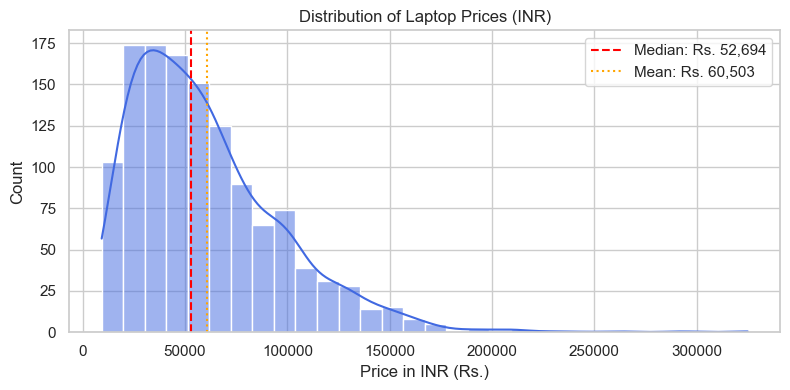

In [20]:
# 1. Target Variable: Price Distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df['Price'], kde=True, color='royalblue', bins=30, ax=ax)
ax.axvline(df['Price'].median(), color='red', linestyle='--', label=f"Median: Rs. {df['Price'].median():,.0f}")
ax.axvline(df['Price'].mean(), color='orange', linestyle=':', label=f"Mean: Rs. {df['Price'].mean():,.0f}")
ax.set_title("Distribution of Laptop Prices (INR)")
ax.set_xlabel("Price in INR (Rs.)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:**
Price is right-skewed, with most laptops costing between ₹25,000 and ₹75,000 and a small tail of premium machines extending above ₹1,50,000.

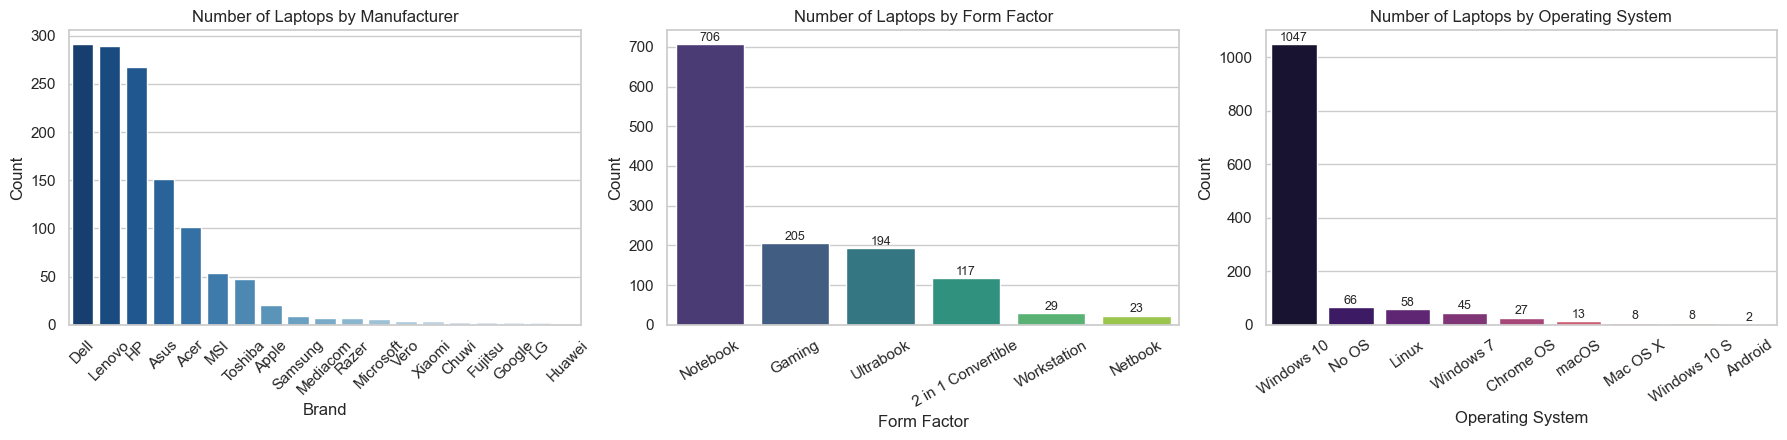

In [21]:
# 2. Categorical Distributions: Manufacturer Brand, Form Factor, and Operating System
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Manufacturer counts
brand_counts = df['Company'].value_counts()
sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='Blues_r', ax=axes[0])
axes[0].set_title("Number of Laptops by Manufacturer")
axes[0].set_xlabel("Brand")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=45)

# Form factor counts
type_counts = df['TypeName'].value_counts()
sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis', ax=axes[1])
axes[1].set_title("Number of Laptops by Form Factor")
axes[1].set_xlabel("Form Factor")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=30)
for i, v in enumerate(type_counts.values):
    axes[1].text(i, v + 8, str(v), ha='center', fontsize=9)

# Operating system counts
opsys_counts = df['OpSys'].value_counts()
sns.barplot(x=opsys_counts.index, y=opsys_counts.values, palette='magma', ax=axes[2])
axes[2].set_title("Number of Laptops by Operating System")
axes[2].set_xlabel("Operating System")
axes[2].set_ylabel("Count")
axes[2].tick_params(axis='x', rotation=35)
for i, v in enumerate(opsys_counts.values):
    axes[2].text(i, v + 12, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

**Observation:**
Dell, Lenovo, and HP make up two-thirds of the market, standard Notebooks are the primary form factor, and Windows 10 is the dominant operating system.

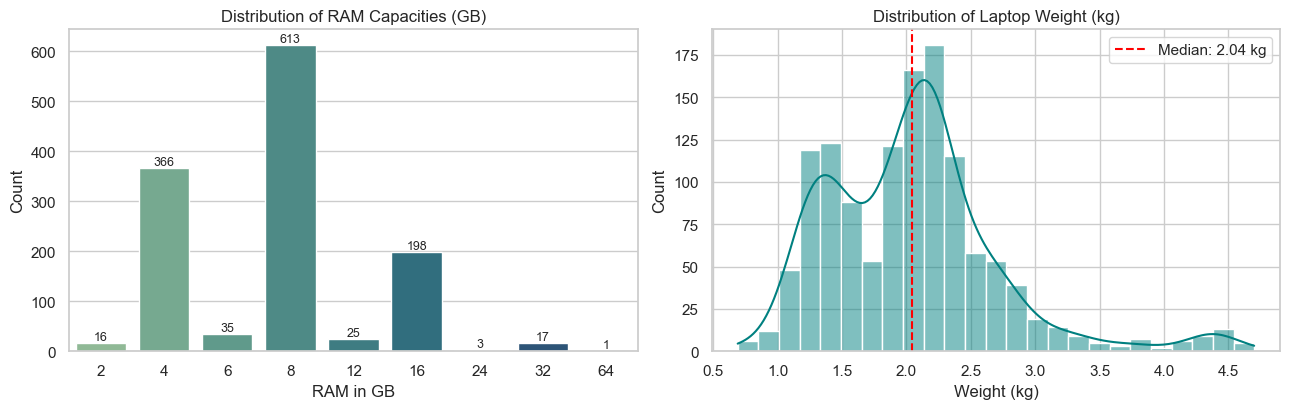

In [22]:
# 3. Hardware Distributions: RAM Capacity and Laptop Weight
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ram_order = sorted(df['Ram_GB'].unique())
sns.countplot(data=df, x='Ram_GB', order=ram_order, palette='crest', ax=axes[0])
axes[0].set_title("Distribution of RAM Capacities (GB)")
axes[0].set_xlabel("RAM in GB")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    h = p.get_height()
    if h > 0: axes[0].annotate(f"{int(h)}", (p.get_x() + p.get_width() / 2., h + 6), ha='center', fontsize=9)

sns.histplot(df['Weight_kg'], kde=True, color='teal', bins=25, ax=axes[1])
axes[1].axvline(df['Weight_kg'].median(), color='red', linestyle='--', label=f"Median: {df['Weight_kg'].median():.2f} kg")
axes[1].set_title("Distribution of Laptop Weight (kg)")
axes[1].set_xlabel("Weight (kg)")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation:**
Most laptops feature 8 GB RAM, and weights are centered around a median of 2.04 kg.

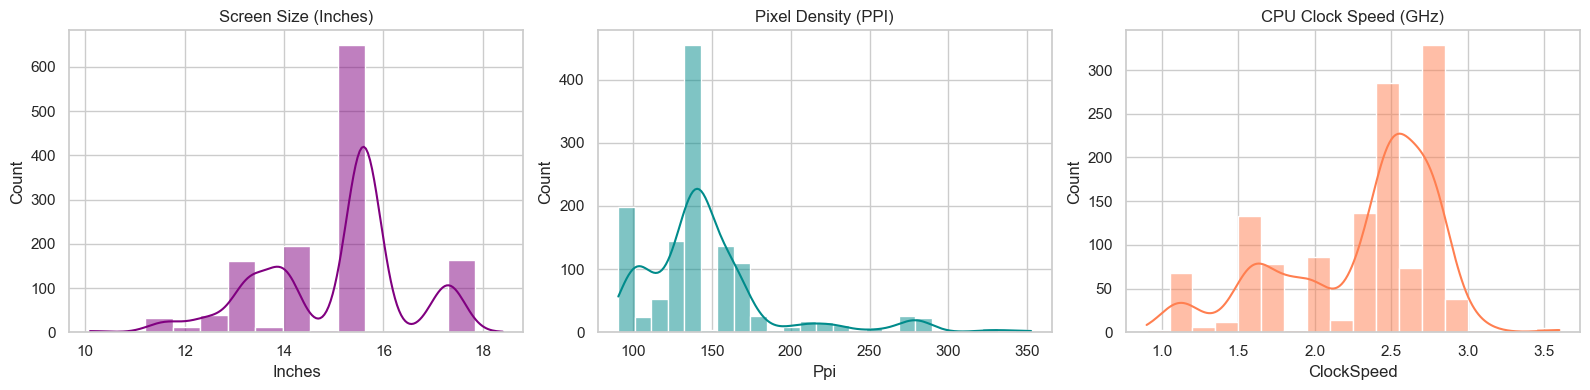

In [23]:
# 4. Display and Processor: Screen Inches, PPI, and Clock Speed
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['Inches'], kde=True, color='purple', bins=15, ax=axes[0])
axes[0].set_title("Screen Size (Inches)")

sns.histplot(df['Ppi'], kde=True, color='darkcyan', bins=25, ax=axes[1])
axes[1].set_title("Pixel Density (PPI)")

sns.histplot(df['ClockSpeed'], kde=True, color='coral', bins=18, ax=axes[2])
axes[2].set_title("CPU Clock Speed (GHz)")

plt.tight_layout()
plt.show()

**Observation:**
Screen sizes peak at 15.6 inches, pixel densities cluster around standard HD and Full HD, and clock speeds center around 2.5 GHz.

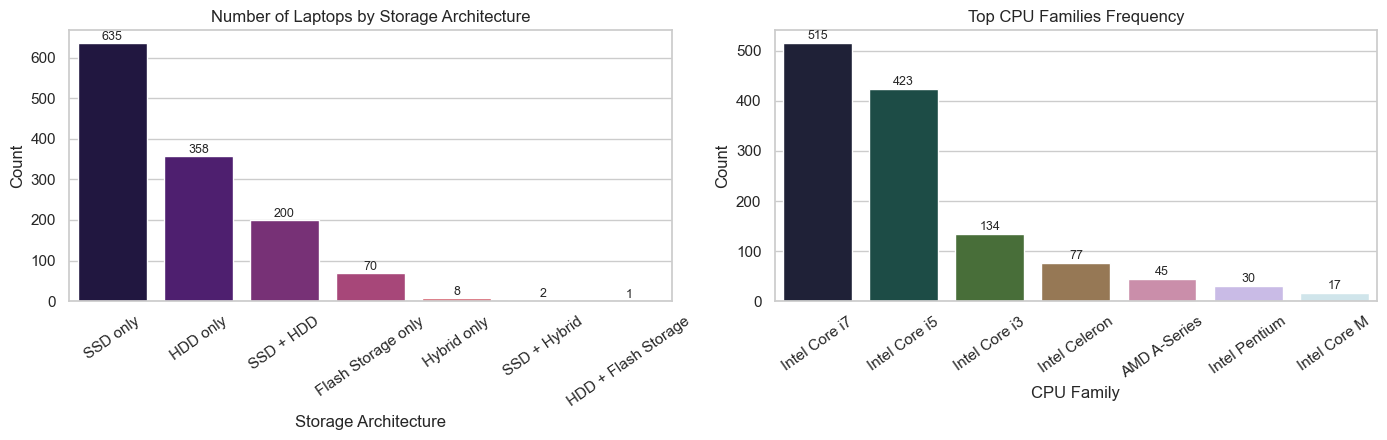

In [24]:
# 5. Storage Configurations and Top CPU Families
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

storage_counts = df['Storage_Configuration'].value_counts()
sns.barplot(x=storage_counts.index, y=storage_counts.values, palette='magma', ax=axes[0])
axes[0].set_title("Number of Laptops by Storage Architecture")
axes[0].set_xlabel("Storage Architecture")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=35)
for i, v in enumerate(storage_counts.values):
    axes[0].text(i, v + 8, str(v), ha='center', fontsize=9)

top_cpus = df['Cpu_Family'].value_counts().head(7)
sns.barplot(x=top_cpus.index, y=top_cpus.values, palette='cubehelix', ax=axes[1])
axes[1].set_title("Top CPU Families Frequency")
axes[1].set_xlabel("CPU Family")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=35)
for i, v in enumerate(top_cpus.values):
    axes[1].text(i, v + 8, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

**Observation:**
SSD-only configurations and Intel Core i7/i5 processors represent the largest share of the market.

---
## 7. Skewness Analysis and Transformation

In [25]:
# Calculate skewness for all numerical features
numerical_features = ['Price', 'Ram_GB', 'Weight_kg', 'Inches', 'Ppi', 'ClockSpeed', 'SSD_GB', 'HDD_GB']

skew_records = []
for col in numerical_features:
    val = df[col].skew()
    if val > 1.0: category = "Highly positively skewed"
    elif val > 0.5: category = "Moderately positively skewed"
    elif val < -1.0: category = "Highly negatively skewed"
    elif val < -0.5: category = "Moderately negatively skewed"
    else: category = "Approximately symmetric"
        
    skew_records.append({
        'Feature': col,
        'Skewness': round(val, 2),
        'Distribution Shape': category
    })

skew_df = pd.DataFrame(skew_records)
print("--- Numerical Features Skewness Table ---")
display(skew_df)

--- Numerical Features Skewness Table ---


,Feature,Skewness,Distribution Shape
0,Price,1.51,Highly positively skewed
1,Ram_GB,2.70,Highly positively skewed
2,Weight_kg,1.15,Highly positively skewed
3,Inches,-0.44,Approximately symmetric
4,Ppi,2.04,Highly positively skewed
5,ClockSpeed,-0.84,Moderately negatively skewed
6,SSD_GB,1.43,Highly positively skewed
7,HDD_GB,0.90,Moderately positively skewed


**Observation:**
Price, RAM, and PPI are positively skewed due to premium configurations, while screen size is approximately symmetric and clock speed is moderately left-skewed. Skewness reflects natural market tiers rather than data errors.

In [26]:
# Evaluate log transformation on the target variable Price
orig_price_skew = df['Price'].skew()
log_price = np.log1p(df['Price'])
log_price_skew = log_price.skew()

print(f"Original Price Skewness:        {orig_price_skew:.2f} (Highly right-skewed)")
print(f"Log-Transformed Price Skewness: {log_price_skew:.2f} (Approximately symmetric)")

Original Price Skewness:        1.51 (Highly right-skewed)
Log-Transformed Price Skewness: -0.18 (Approximately symmetric)


**Observation:**
Log transformation reduces Price skewness from +1.51 to -0.18, producing an approximately symmetric distribution.

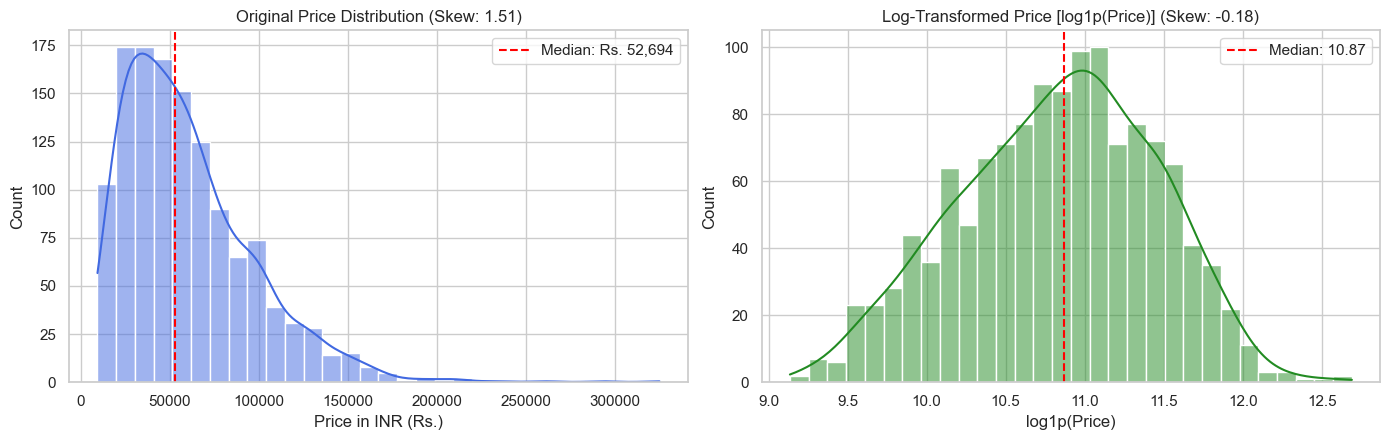

In [27]:
# Compare original vs. log-transformed Price distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df['Price'], kde=True, color='royalblue', bins=30, ax=axes[0])
axes[0].axvline(df['Price'].median(), color='red', linestyle='--', label=f"Median: Rs. {df['Price'].median():,.0f}")
axes[0].set_title(f"Original Price Distribution (Skew: {orig_price_skew:.2f})")
axes[0].set_xlabel("Price in INR (Rs.)")
axes[0].set_ylabel("Count")
axes[0].legend()

sns.histplot(log_price, kde=True, color='forestgreen', bins=30, ax=axes[1])
axes[1].axvline(log_price.median(), color='red', linestyle='--', label=f"Median: {log_price.median():.2f}")
axes[1].set_title(f"Log-Transformed Price [log1p(Price)] (Skew: {log_price_skew:.2f})")
axes[1].set_xlabel("log1p(Price)")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation:**
Log transformation compresses the long right tail of Price into a balanced bell shape, though it does not guarantee a strictly normal distribution.

---
## 8. Bivariate Analysis (Features vs. Price)

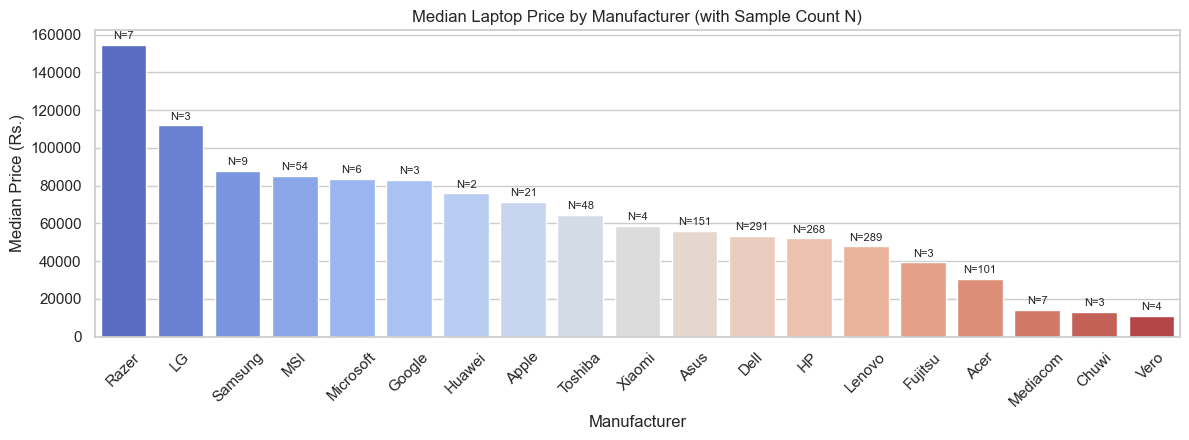

In [28]:
# 1. Company vs Price (Median Price Comparison with Sample Counts)
company_stats = df.groupby('Company').agg(
    Median_Price=('Price', 'median'),
    Sample_Count=('Price', 'count')
).sort_values(by='Median_Price', ascending=False)

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.barplot(x=company_stats.index, y=company_stats['Median_Price'], palette='coolwarm', ax=ax)
ax.set_title("Median Laptop Price by Manufacturer (with Sample Count N)")
ax.set_xlabel("Manufacturer")
ax.set_ylabel("Median Price (Rs.)")
plt.xticks(rotation=45)

for i, company in enumerate(company_stats.index):
    count = company_stats.loc[company, 'Sample_Count']
    price = company_stats.loc[company, 'Median_Price']
    ax.text(i, price + 3000, f"N={count}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Observation:**
Razer and LG show the highest median prices, but their small sample sizes reflect niche premium models. Mainstream brands (Dell, HP, Lenovo) span all price tiers.

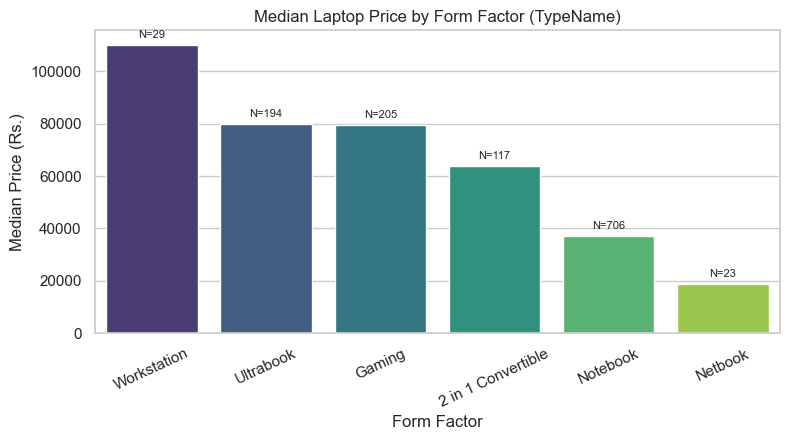

In [29]:
# 2. TypeName vs Price (Median Price Comparison with Sample Counts)
type_stats = df.groupby('TypeName').agg(
    Median_Price=('Price', 'median'),
    Sample_Count=('Price', 'count')
).sort_values(by='Median_Price', ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=type_stats.index, y=type_stats['Median_Price'], palette='viridis', ax=ax)
ax.set_title("Median Laptop Price by Form Factor (TypeName)")
ax.set_xlabel("Form Factor")
ax.set_ylabel("Median Price (Rs.)")
plt.xticks(rotation=25)

for i, t in enumerate(type_stats.index):
    count = type_stats.loc[t, 'Sample_Count']
    price = type_stats.loc[t, 'Median_Price']
    ax.text(i, price + 2500, f"N={count}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Observation:**
Workstations, Gaming laptops, and Ultrabooks have higher median prices than standard Notebooks and Netbooks.

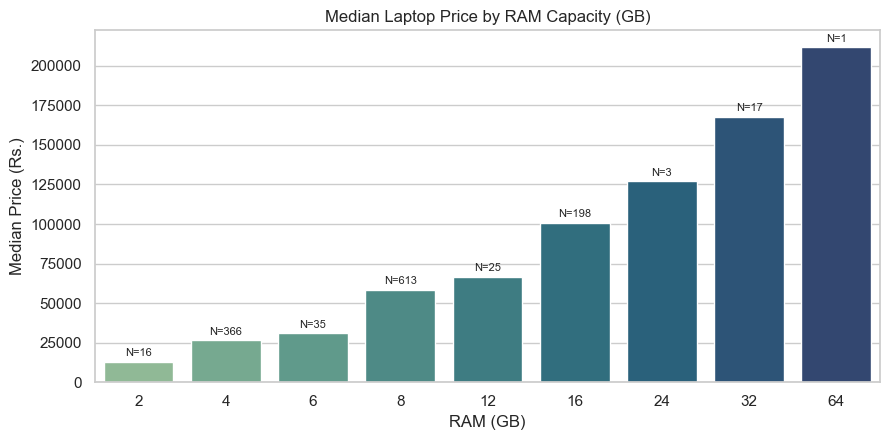

In [30]:
# 3. RAM vs Price (Median Price Comparison with Sample Counts)
ram_stats = df.groupby('Ram_GB').agg(
    Median_Price=('Price', 'median'),
    Sample_Count=('Price', 'count')
).sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=ram_stats.index, y=ram_stats['Median_Price'], palette='crest', ax=ax)
ax.set_title("Median Laptop Price by RAM Capacity (GB)")
ax.set_xlabel("RAM (GB)")
ax.set_ylabel("Median Price (Rs.)")

for i, ram in enumerate(ram_stats.index):
    count = ram_stats.loc[ram, 'Sample_Count']
    price = ram_stats.loc[ram, 'Median_Price']
    ax.text(i, price + 3500, f"N={count}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Observation:**
Laptops with higher RAM generally have higher median prices, though these machines also bundle faster processors and dedicated graphics.

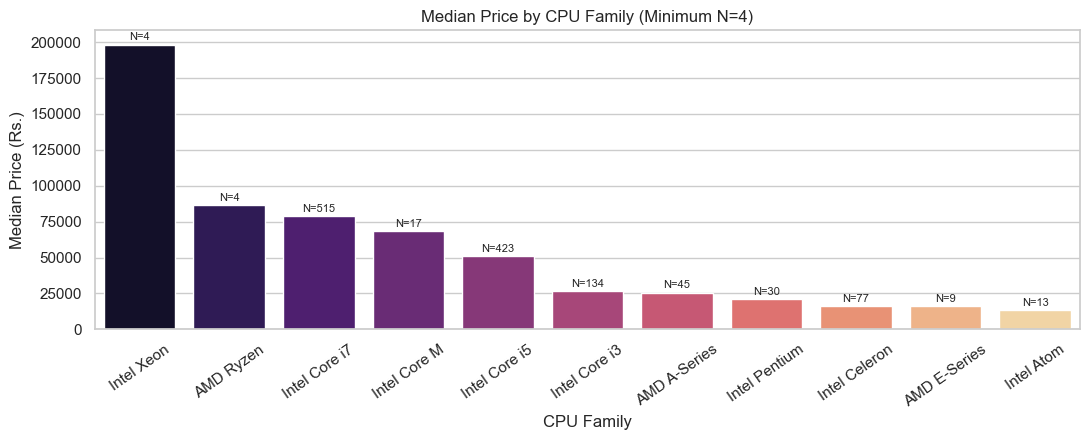

In [31]:
# 4. CPU Family vs Price (Top CPU Families Ranked by Median Price)
cpu_stats = df.groupby('Cpu_Family').agg(
    Median_Price=('Price', 'median'),
    Sample_Count=('Price', 'count')
).sort_values(by='Median_Price', ascending=False)

top_cpu_stats = cpu_stats[cpu_stats['Sample_Count'] >= 4]

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=top_cpu_stats.index, y=top_cpu_stats['Median_Price'], palette='magma', ax=ax)
ax.set_title("Median Price by CPU Family (Minimum N=4)")
ax.set_xlabel("CPU Family")
ax.set_ylabel("Median Price (Rs.)")
plt.xticks(rotation=35)

for i, cpu in enumerate(top_cpu_stats.index):
    count = top_cpu_stats.loc[cpu, 'Sample_Count']
    price = top_cpu_stats.loc[cpu, 'Median_Price']
    ax.text(i, price + 3000, f"N={count}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Observation:**
Intel Xeon and Core i7 laptops command higher median prices than Core i5, Core i3, and Celeron models.

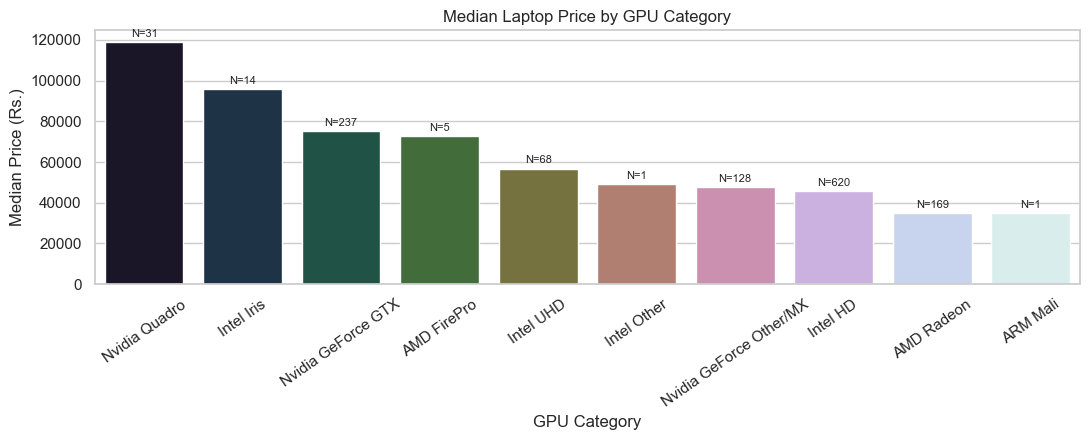

In [32]:
# 5. GPU Category vs Price (Median Price Comparison with Sample Counts)
gpu_stats = df.groupby('Gpu_Category').agg(
    Median_Price=('Price', 'median'),
    Sample_Count=('Price', 'count')
).sort_values(by='Median_Price', ascending=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=gpu_stats.index, y=gpu_stats['Median_Price'], palette='cubehelix', ax=ax)
ax.set_title("Median Laptop Price by GPU Category")
ax.set_xlabel("GPU Category")
ax.set_ylabel("Median Price (Rs.)")
plt.xticks(rotation=35)

for i, gpu in enumerate(gpu_stats.index):
    count = gpu_stats.loc[gpu, 'Sample_Count']
    price = gpu_stats.loc[gpu, 'Median_Price']
    ax.text(i, price + 2500, f"N={count}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Observation:**
Nvidia Quadro and GeForce GTX graphics are associated with higher median prices compared to mainstream Intel HD graphics.

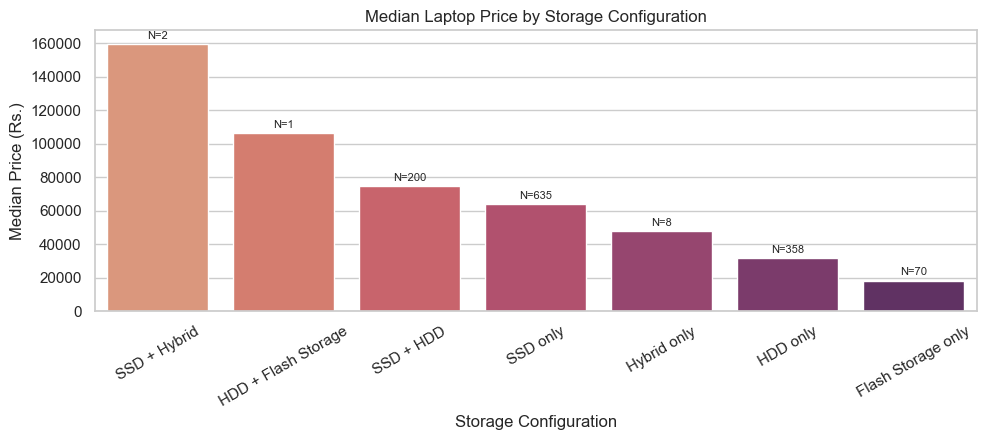

In [33]:
# 6. Storage Configuration vs Price (Median Price Comparison with Sample Counts)
storage_stats = df.groupby('Storage_Configuration').agg(
    Median_Price=('Price', 'median'),
    Sample_Count=('Price', 'count')
).sort_values(by='Median_Price', ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=storage_stats.index, y=storage_stats['Median_Price'], palette='flare', ax=ax)
ax.set_title("Median Laptop Price by Storage Configuration")
ax.set_xlabel("Storage Configuration")
ax.set_ylabel("Median Price (Rs.)")
plt.xticks(rotation=30)

for i, st in enumerate(storage_stats.index):
    count = storage_stats.loc[st, 'Sample_Count']
    price = storage_stats.loc[st, 'Median_Price']
    ax.text(i, price + 3000, f"N={count}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Observation:**
SSD and dual SSD + HDD configurations have substantially higher median prices than mechanical HDD-only and Flash-only laptops.

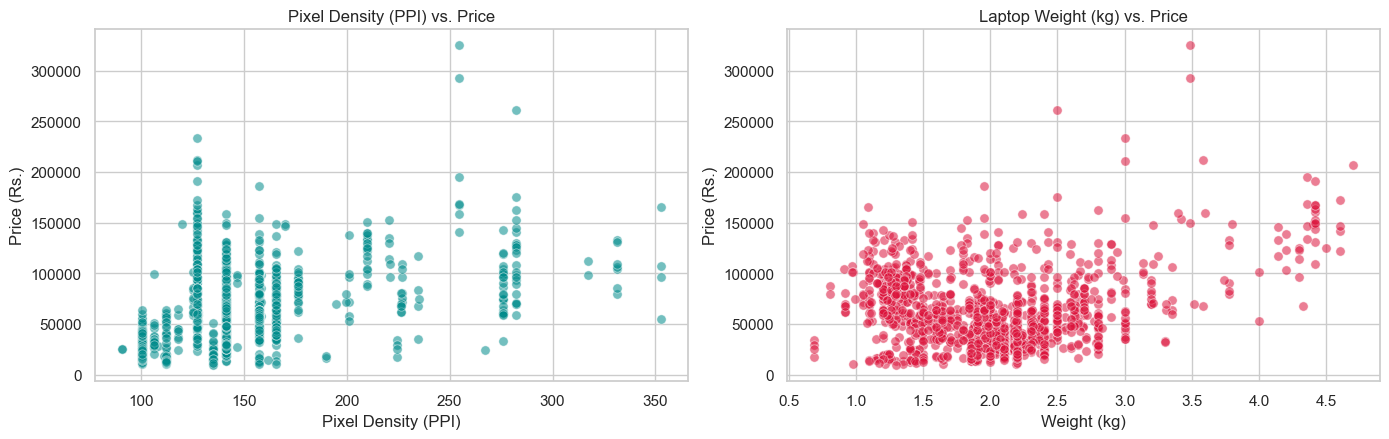

In [34]:
# 7. PPI vs Price & 8. Weight vs Price (Scatterplots)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.scatterplot(data=df, x='Ppi', y='Price', alpha=0.55, color='darkcyan', s=45, ax=axes[0])
axes[0].set_title("Pixel Density (PPI) vs. Price")
axes[0].set_xlabel("Pixel Density (PPI)")
axes[0].set_ylabel("Price (Rs.)")

sns.scatterplot(data=df, x='Weight_kg', y='Price', alpha=0.55, color='crimson', s=45, ax=axes[1])
axes[1].set_title("Laptop Weight (kg) vs. Price")
axes[1].set_xlabel("Weight (kg)")
axes[1].set_ylabel("Price (Rs.)")

plt.tight_layout()
plt.show()

**Observation:**
Higher pixel density generally relates to higher prices. Very light ultrabooks and very heavy gaming laptops both show higher median prices than mainstream mid-weight laptops.

---
## 9. Multivariate Analysis

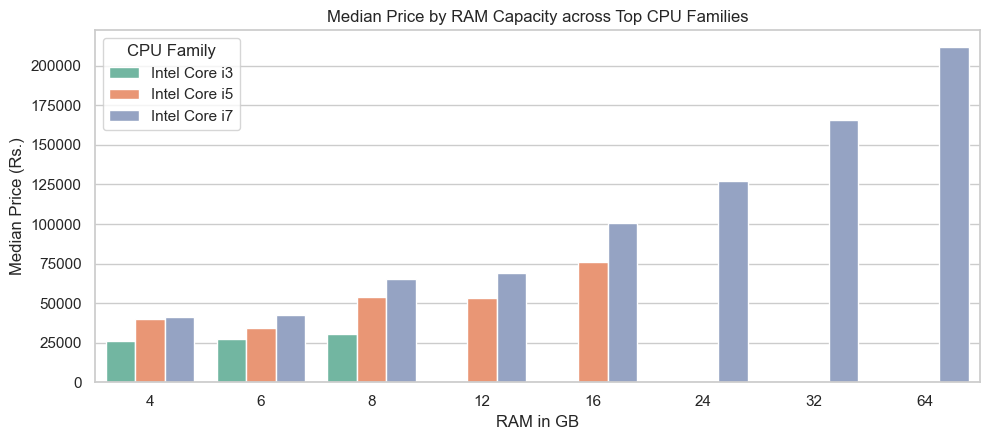

In [35]:
# 1. RAM, CPU Family, and Price Interaction
top_3_cpus = df[df['Cpu_Family'].isin(['Intel Core i7', 'Intel Core i5', 'Intel Core i3'])]
cpu_ram_stats = top_3_cpus.groupby(['Cpu_Family', 'Ram_GB'])['Price'].median().reset_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=cpu_ram_stats, x='Ram_GB', y='Price', hue='Cpu_Family', palette='Set2', ax=ax)
ax.set_title("Median Price by RAM Capacity across Top CPU Families")
ax.set_xlabel("RAM in GB")
ax.set_ylabel("Median Price (Rs.)")
ax.legend(title="CPU Family")

plt.tight_layout()
plt.show()

**Observation:**
Higher RAM is associated with higher median prices across all processor tiers, with the largest price increases seen in Core i7 configurations.

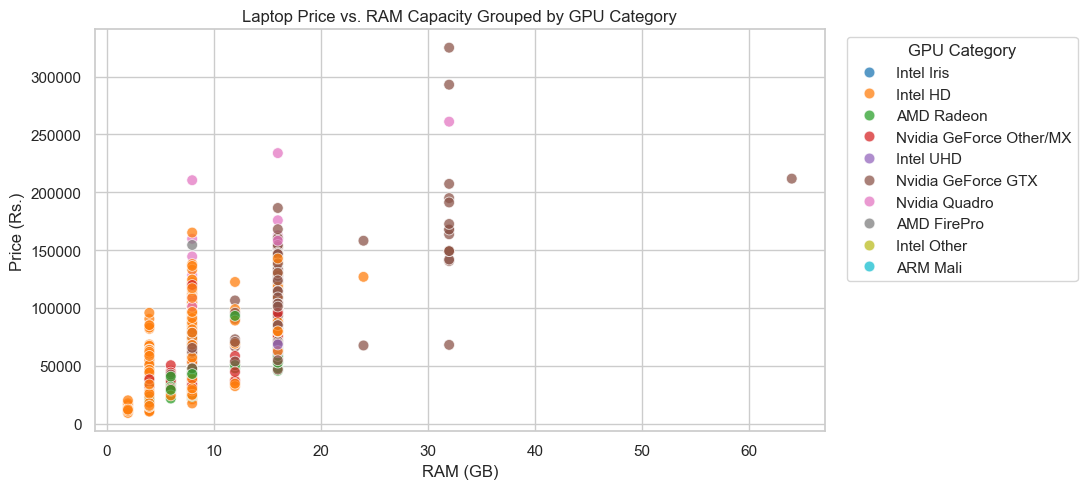

In [36]:
# 2. GPU Category, RAM, and Price Interaction
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(data=df, x='Ram_GB', y='Price', hue='Gpu_Category', palette='tab10', s=60, alpha=0.75, ax=ax)
ax.set_title("Laptop Price vs. RAM Capacity Grouped by GPU Category")
ax.set_xlabel("RAM (GB)")
ax.set_ylabel("Price (Rs.)")
ax.legend(title="GPU Category", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Observation:**
Premium laptops above ₹1,00,000 predominantly pair high RAM with dedicated Nvidia GTX or Quadro graphics.

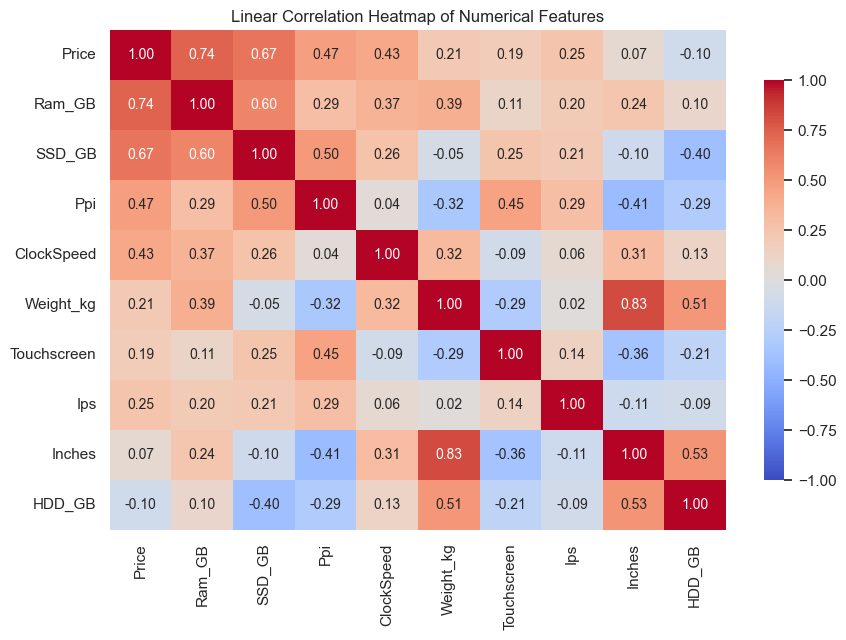

In [37]:
# 3. Correlation Heatmap of Numerical Features
numerical_cols = ['Price', 'Ram_GB', 'SSD_GB', 'Ppi', 'ClockSpeed', 'Weight_kg', 'Touchscreen', 'Ips', 'Inches', 'HDD_GB']
correlation_matrix = df[numerical_cols].corr()

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title("Linear Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

**Observation:**
RAM and SSD capacity show the strongest positive linear correlations with price. HDD capacity shows a weak negative correlation because mechanical drives are primarily found in budget laptops.


## 10. Outlier Investigation

In [38]:
# Calculate IQR boundaries and statistical outlier counts on the clean dataset
eval_features = ['Ram_GB', 'Weight_kg', 'ClockSpeed', 'Ppi', 'Price', 'SSD_GB', 'HDD_GB']
iqr_records = []

for feat in eval_features:
    q1 = df[feat].quantile(0.25)
    med = df[feat].median()
    q3 = df[feat].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[feat] < lower_bound) | (df[feat] > upper_bound)]
    count = len(outliers)
    pct = round((count / len(df)) * 100, 2)
    
    iqr_records.append({
        'Feature': feat,
        'Q1 (25%)': round(q1, 2),
        'Median': round(med, 2),
        'Q3 (75%)': round(q3, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': count,
        'Outlier Pct (%)': pct
    })

df_iqr_summary = pd.DataFrame(iqr_records)
print("--- IQR Outlier Summary on Clean Dataset (N = 1,274) ---")
display(df_iqr_summary)

--- IQR Outlier Summary on Clean Dataset (N = 1,274) ---


,Feature,Q1 (25%),Median,Q3 (75%),Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,Ram_GB,4.00,8.00,8.00,-2.00,14.00,219,17.19
1,Weight_kg,1.50,2.04,2.31,0.28,3.53,45,3.53
2,ClockSpeed,2.00,2.50,2.70,0.95,3.75,2,0.16
3,Ppi,127.34,141.21,157.35,82.31,202.37,114,8.95
4,Price,32495.61,52693.92,79773.48,-38421.21,150690.29,28,2.20
5,SSD_GB,0.00,256.00,256.00,-384.00,640.00,18,1.41
6,HDD_GB,0.00,0.00,1024.00,-1536.00,2560.00,0,0.00


In [39]:
# Inspect top price outliers above the IQR upper threshold
price_upper = df_iqr_summary.loc[df_iqr_summary['Feature'] == 'Price', 'Upper Bound'].values[0]
high_price_laptops = df[df['Price'] > price_upper].sort_values(by='Price', ascending=False)

print(f"Total price outliers above Rs. {price_upper:,.2f}: {len(high_price_laptops)}")
print("\nTop 5 Most Expensive Laptops in the Dataset:")
display(high_price_laptops[['Company', 'TypeName', 'Cpu', 'Ram_GB', 'Memory', 'Gpu', 'Price']].head(5))

Total price outliers above Rs. 150,690.29: 28

Top 5 Most Expensive Laptops in the Dataset:


,Company,TypeName,Cpu,Ram_GB,Memory,Gpu,Price
196,Razer,Gaming,Intel Core i7 7820HK 2.9GHz,32,1TB SSD,Nvidia GeForce GTX 1080,324954.72
830,Razer,Gaming,Intel Core i7 7820HK 2.9GHz,32,512GB SSD,Nvidia GeForce GTX 1080,292986.72
610,Lenovo,Notebook,Intel Xeon E3-1535M v6 3.1GHz,32,1TB SSD,Nvidia Quadro M2200M,261018.72
749,HP,Workstation,Intel Xeon E3-1535M v5 2.9GHz,16,256GB SSD,Nvidia Quadro M2000M,233845.92
1066,Asus,Gaming,Intel Core i7 6820HK 2.7GHz,64,1TB SSD,Nvidia GeForce GTX 980,211788.00


**Observation & Outlier Decisions:**
The 28 price outliers above ₹1,50,690 represent high-end gaming laptops and mobile workstations with premium components (Core i7/Xeon, 32–64 GB RAM, discrete GPUs). They are retained without clipping or removal because their specifications are internally consistent.